In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
pd.set_option('display.max_columns', 30)

In [5]:
# названия колонок по документации NASA
cols = ['engine_id', 'cycle'] + \
       [f'os_{i}' for i in range(1, 4)] + \
       [f'sensor_{i}' for i in range(1, 22)]


In [6]:
train = pd.read_csv('train_FD001.txt', sep=r'\s+', header=None, names=cols)
test  = pd.read_csv('test_FD001.txt',  sep=r'\s+', header=None, names=cols)
rul_test = pd.read_csv('RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL_true'])

In [7]:
print(f'train: {train.shape}')
print(f'test:  {test.shape}')
train.head()

train: (20631, 26)
test:  (13096, 26)


,engine_id,cycle,os_1,os_2,os_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Из набора данных видно, что параметры сенсоров неизвестны

In [8]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
engine_id,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
os_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
os_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
os_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


Пропусков нет, столбцы там где отклонение равно нулю на протяжении всего датасета постоянны и сами по себе не будут влиять на обучение модели.
Вообще данные не сильно изменяются в пределах датасета, что характерно для работы двигателя.

Построим графики сенсоров, которые имеют не нулевое стандартное отклонения

In [9]:
zero_std = train.std(numeric_only=True)
zero_cols = zero_std[zero_std == 0].index.tolist()
print('Константные:', zero_cols)

sensors = [c for c in train.columns
           if c.startswith('sensor') and c not in zero_cols]
print(f'Анализируем {len(sensors)} сенсоров')

Константные: ['os_3', 'sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']
Анализируем 17 сенсоров


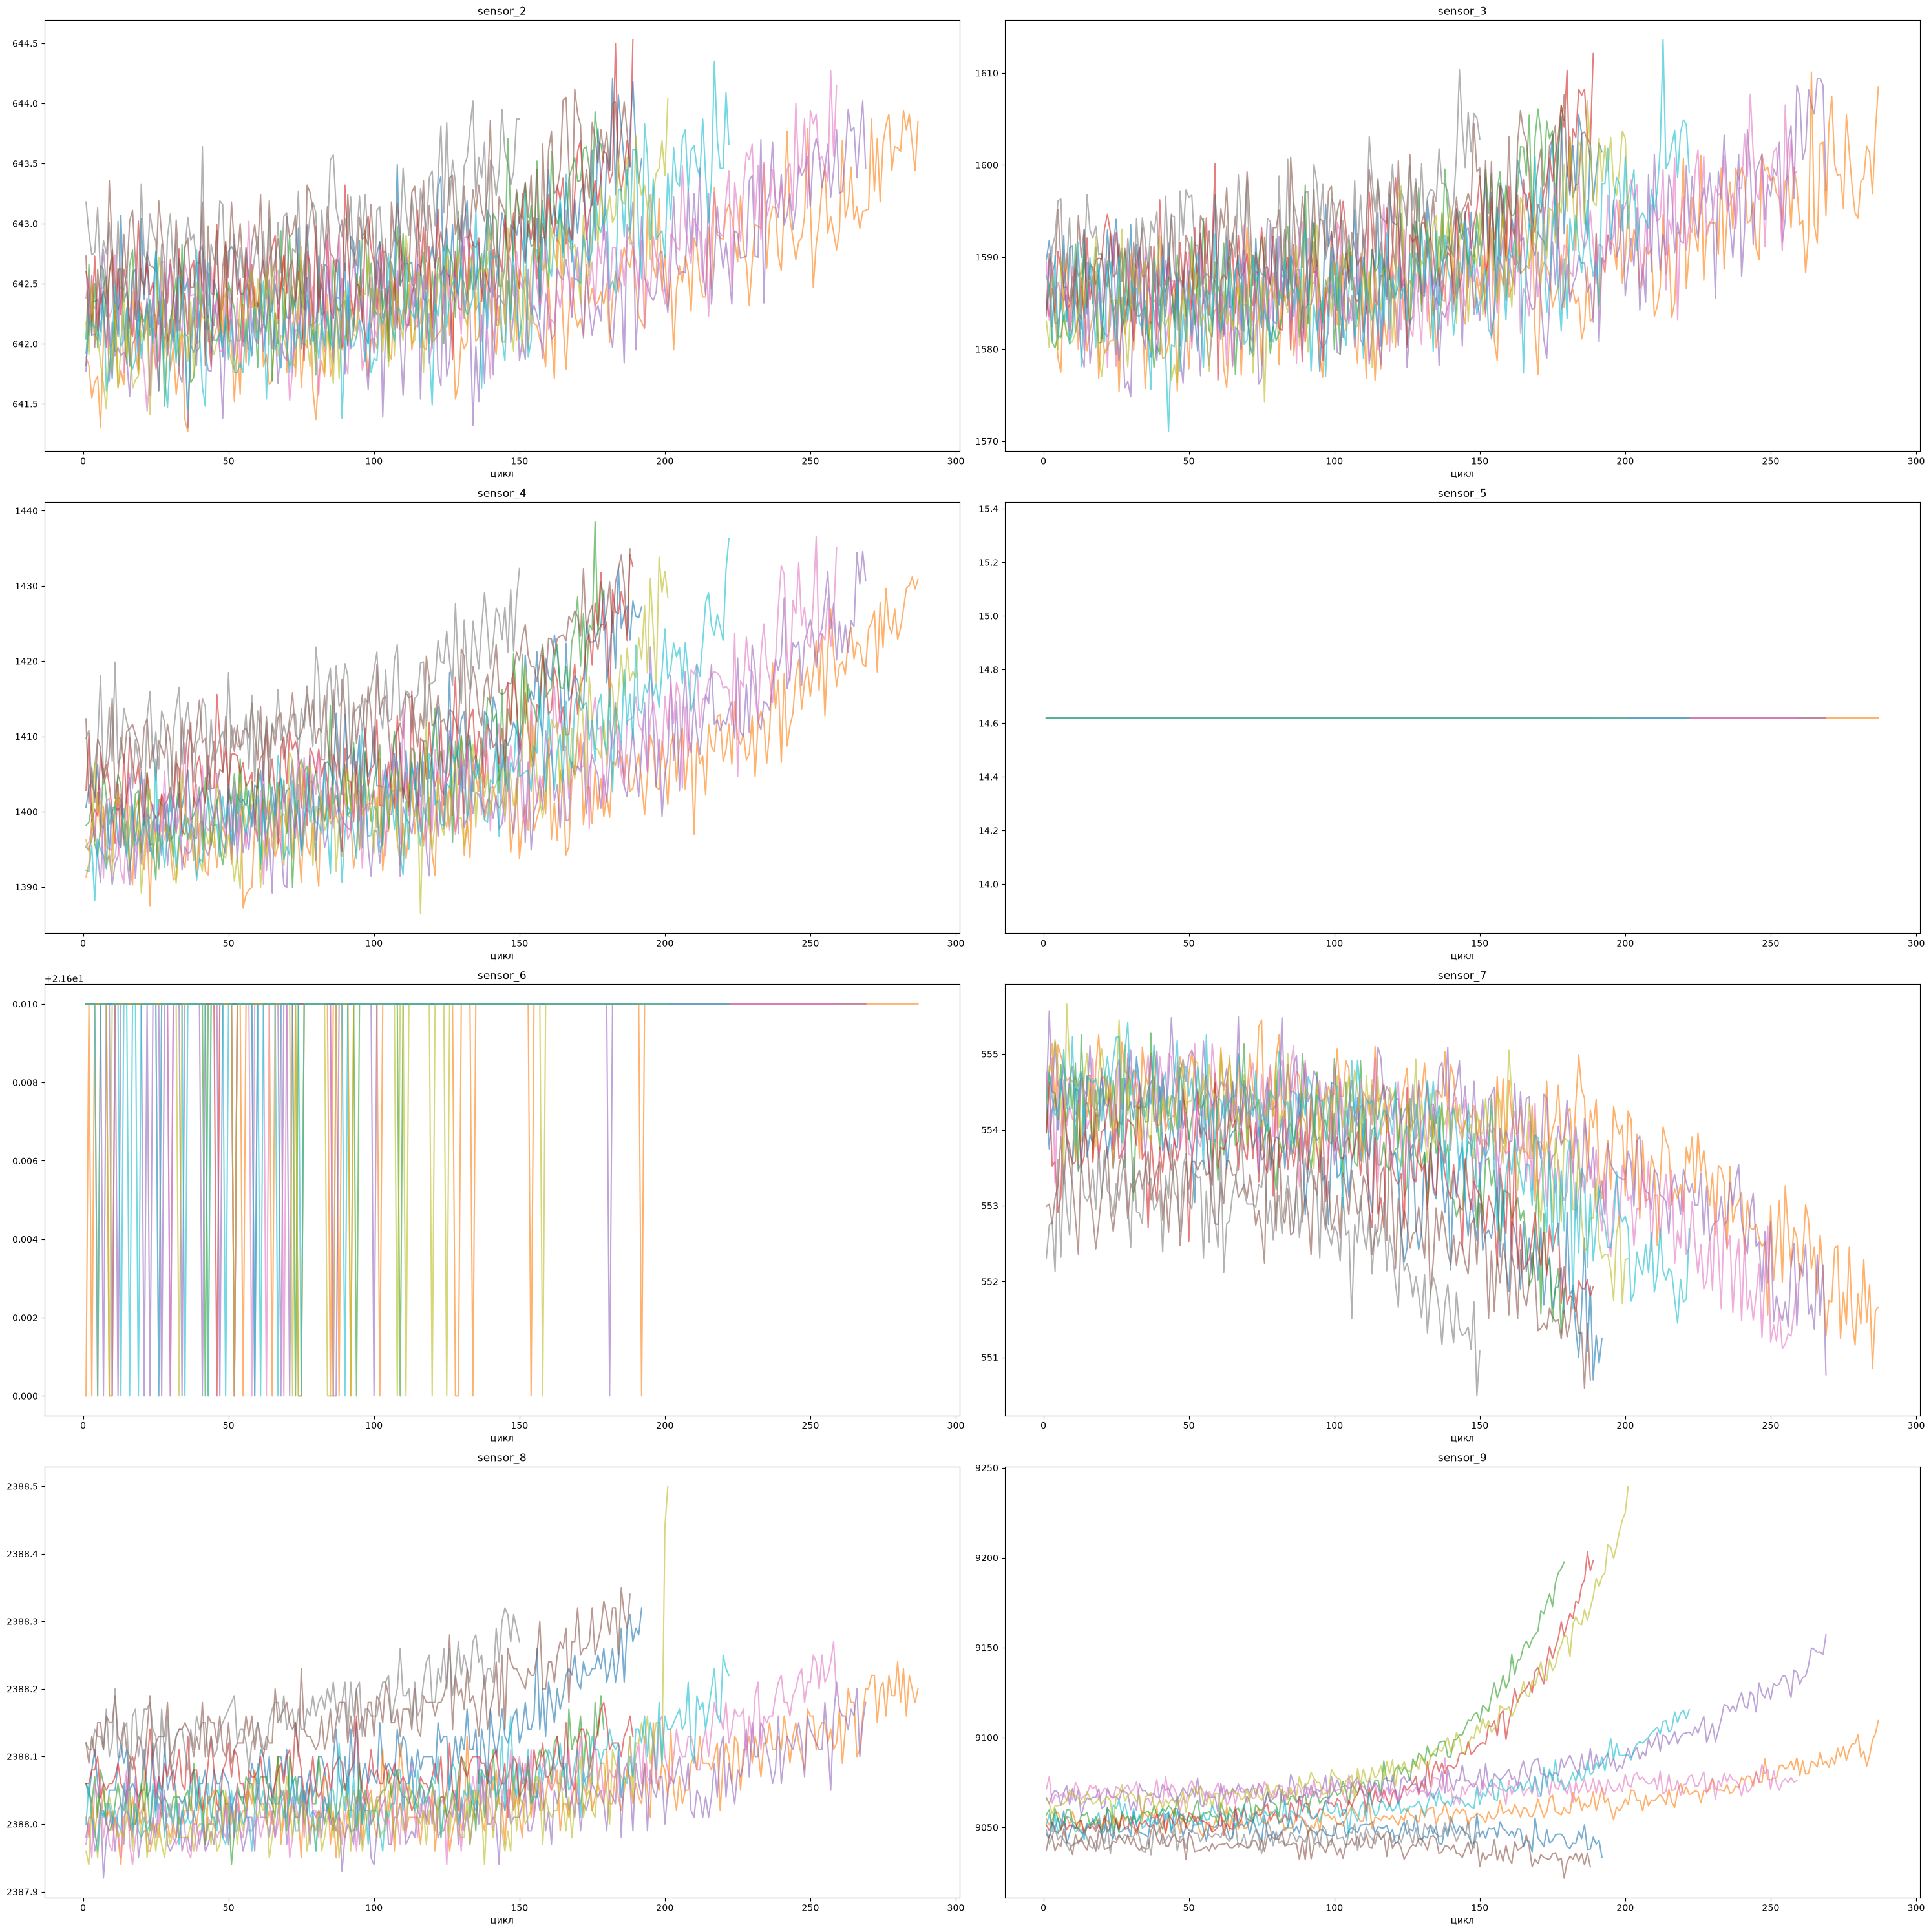

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(30, 30))
sensors_to_plot = sensors 
for ax, s in zip(axes.flat, sensors_to_plot):
    for eng in train['engine_id'].unique()[:10]:   # первые 10 двигателей
        df = train[train['engine_id'] == eng]
        ax.plot(df['cycle'], df[s], alpha=0.6)
    ax.set_title(s)
    ax.set_xlabel('цикл')

plt.tight_layout()
plt.show()

Ресурс двигателей до отказа

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


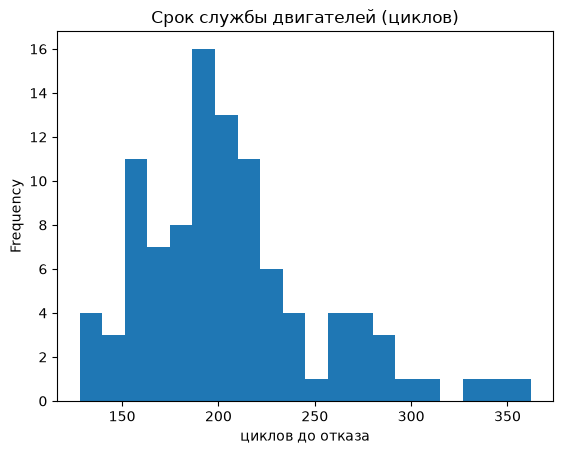

In [11]:
lifetimes = train.groupby('engine_id')['cycle'].max()
print(lifetimes.describe())

lifetimes.plot.hist(bins=20, title='Срок службы двигателей (циклов)')
plt.xlabel('циклов до отказа')
plt.show()

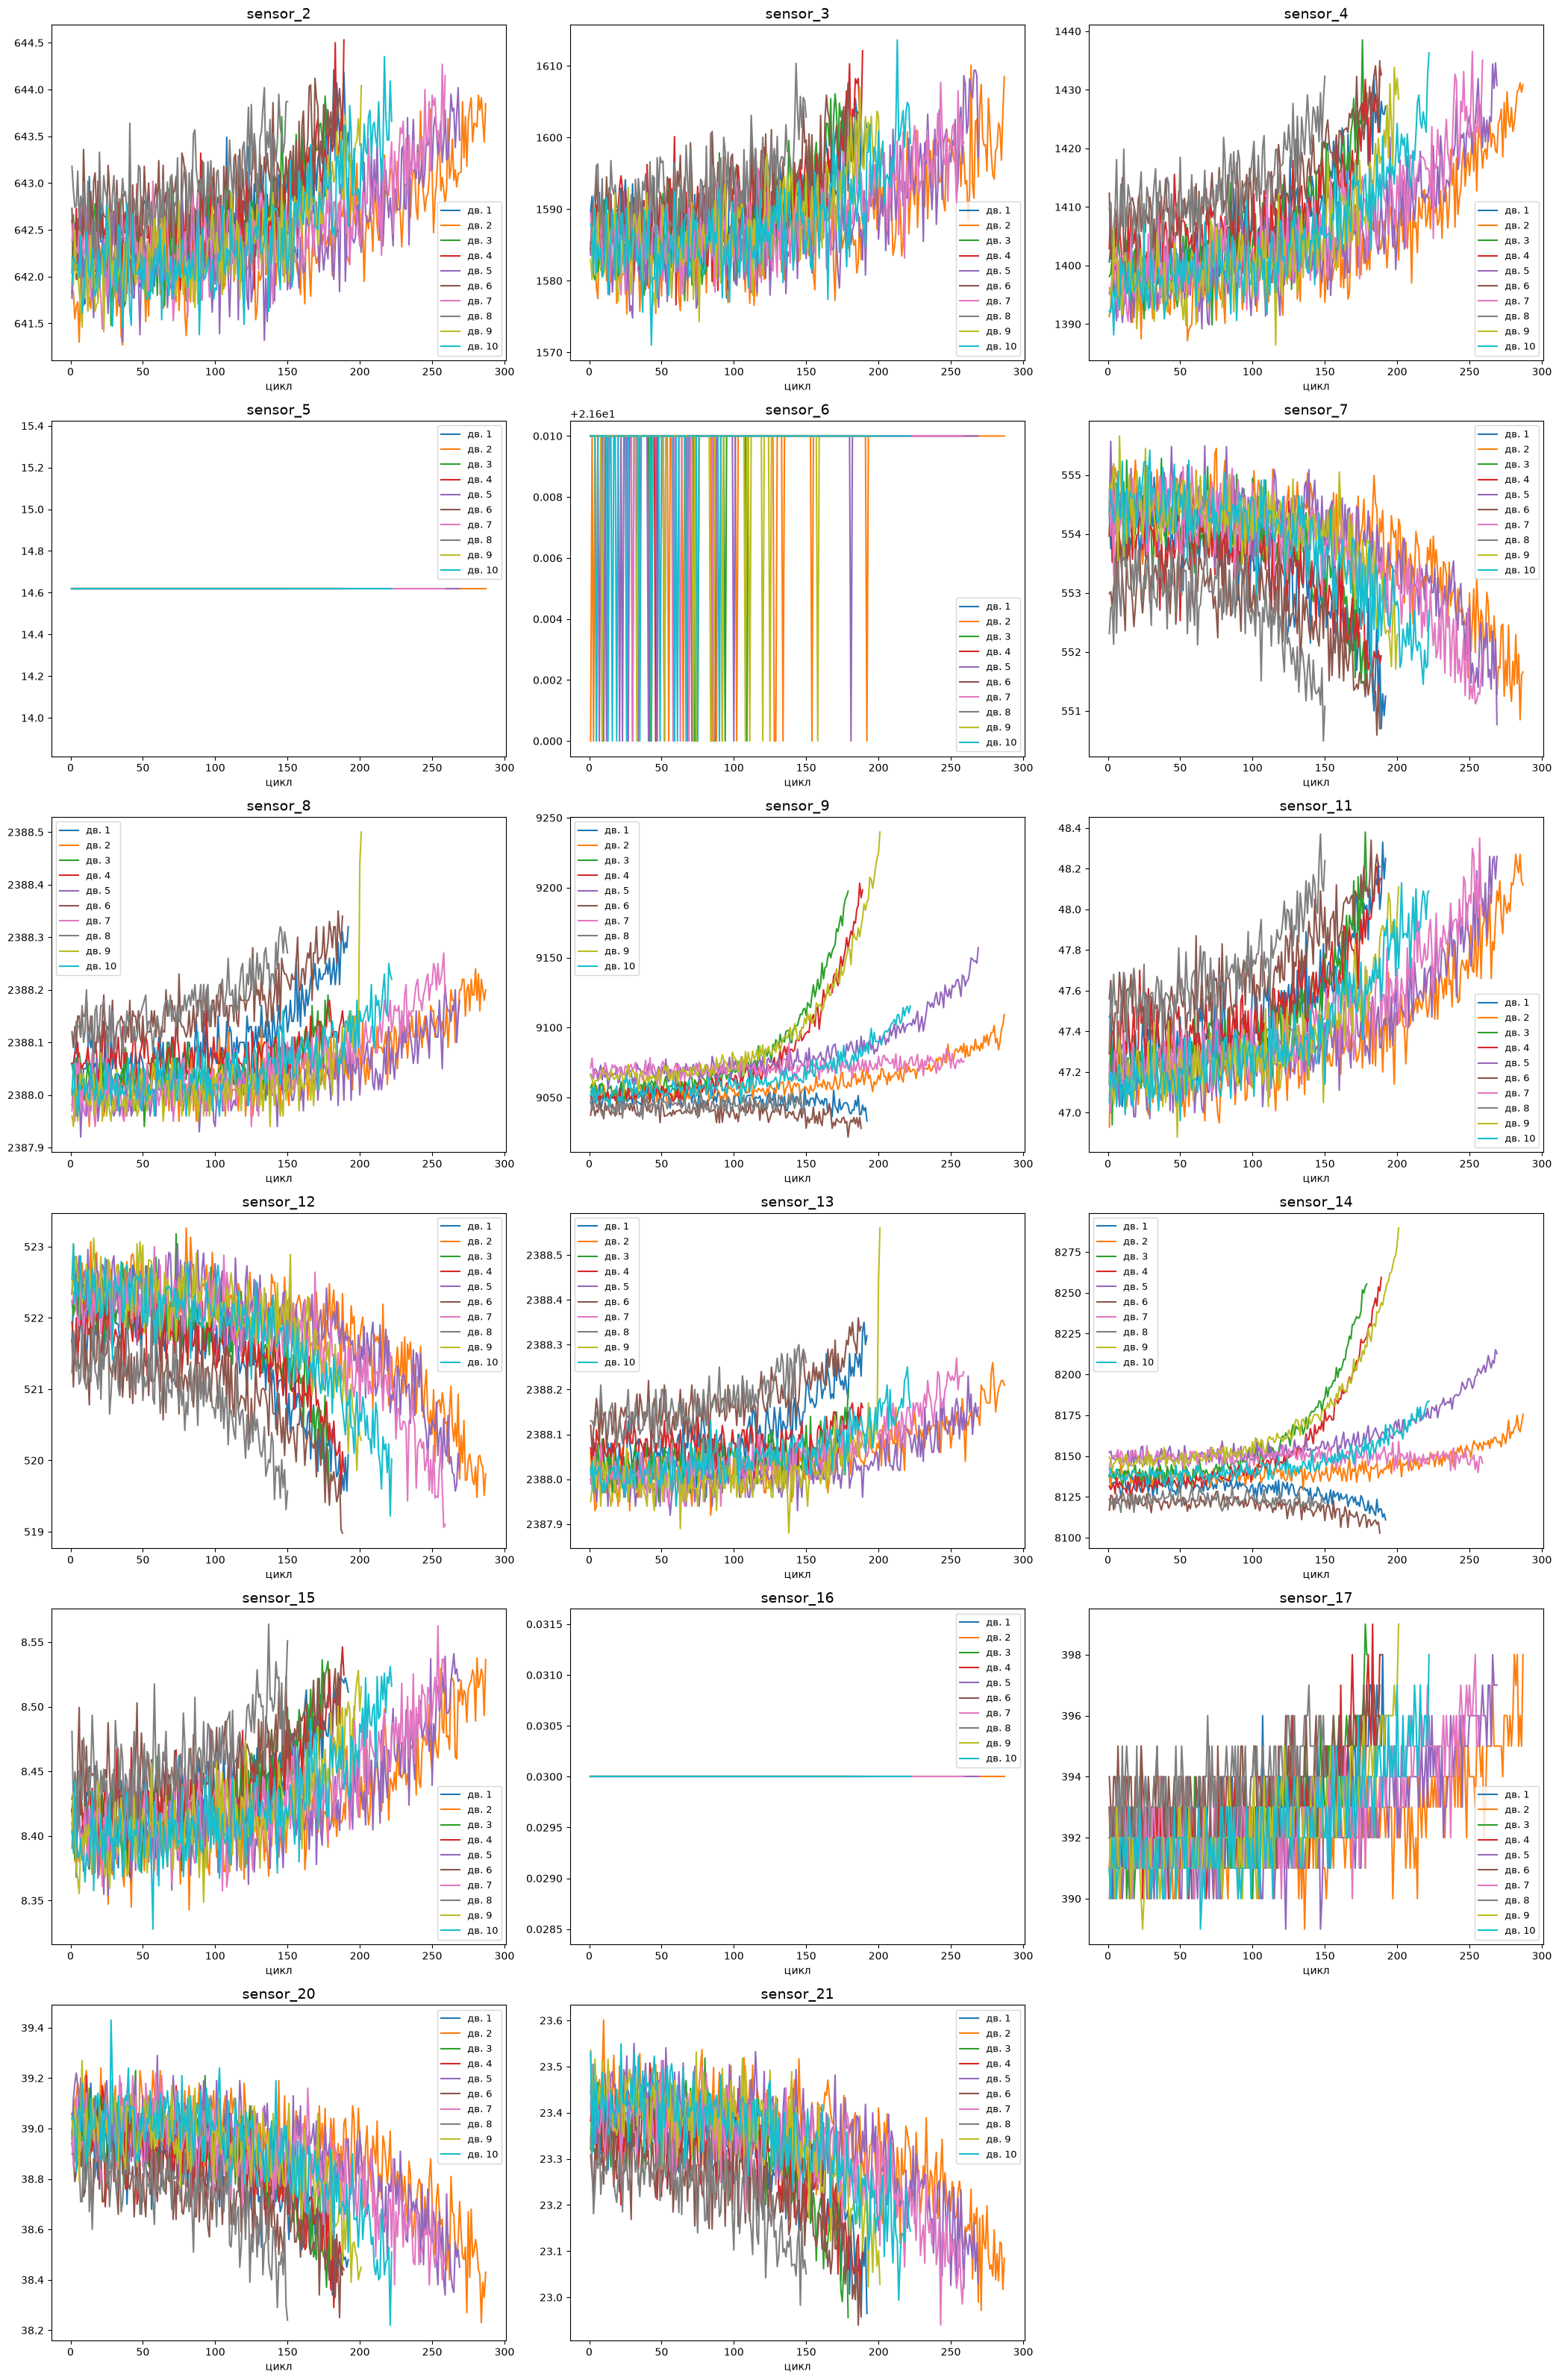

In [13]:
engines = sorted(train['engine_id'].unique())[:10]   # двигатели 1–10
sub = train[train['engine_id'].isin(engines)]

fig, axes = plt.subplots(6, 3, figsize=(21, 32))     # 17 сенсоров → 18 ячеек
for ax, s in zip(axes.flat, sensors):
    for eng in engines:
        df = sub[sub['engine_id'] == eng]
        ax.plot(df['cycle'], df[s], label=f'дв. {eng}')
    ax.set_title(s, fontsize=14)
    ax.set_xlabel('цикл')
    ax.legend(fontsize=9)

axes.flat[-1].axis('off')   # последняя ячейка пустая — выключаем
plt.tight_layout()
plt.show()